# Phase 6 scratch: patterns worth telling
Rings were chosen in Phase 4 with training-period labels only. Here we *describe* those 44 rings using all labels (days 1 to 182). Nothing in this notebook feeds a model or the Phase 5 comparison, so using later labels for description is fine.

In [1]:
import sys
sys.path.insert(0, '../../src')
import pandas as pd, graph, patterns, viz
pd.set_option('display.width', 250)
con = graph.connect()
t = patterns.ring_frame(con)

## 1. What a ring looks like

In [2]:
patterns.ring_shape(t)

{'rings': 44,
 'identities': 225,
 'median_size': 4.0,
 'max_size': 16,
 'device_link_share': 0.67,
 'card_link_share': 0.34,
 'email_link_share': 0.0,
 'ring_txns': 545,
 'ring_fraud_rate': 0.712,
 'median_fraud_txns_per_member': 1.0,
 'members_with_1_or_2_fraud_txns': 0.775,
 'median_fraud_days': 13.5,
 'rings_fraud_in_one_day': 0.341}

Small (median 4 identities, max 16), linked mostly by a shared device (67% of links), never by email once common domains are suppressed. Each member identity is a near-burner: the median member commits 1 fraud transaction and 78% commit 1 or 2. Fraud inside a ring runs a median of 13.5 days, and 34% of rings do all their fraud in a single day.

## 2. Ring members start together
For each ring, sort members by the day of their first fraud and measure the gap to the previous member. Baseline: random pairs of fraud identities.

In [3]:
co = patterns.coordination(t)
co.round(3)

,pairs,same_day,within_7_days,median_gap_days
group,,,,
Ring members,107,0.561,0.776,0.0
Random pairs of fraudsters,50000,0.006,0.082,52.0


PosixPath('/Users/keke/fraud-ring-hunter/figures/06_ring_coordination.png')

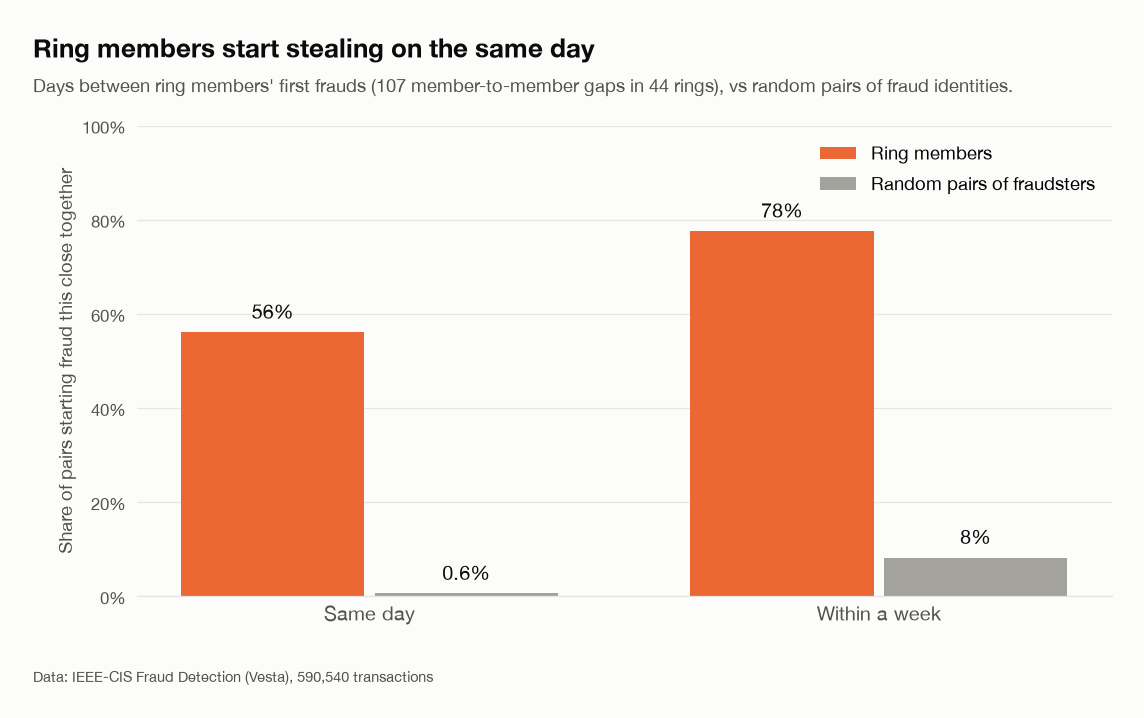

In [4]:
fig = patterns.plot_coordination(co)
viz.save(fig, '06_ring_coordination')

56% of ring members start on the same day as the previous member, against 0.6% for random fraud pairs; 78% within a week against 8%.

Caveat: we cannot tell whether a ring is several people or one person running several cards. Shared device plus same-day starts fits both, so this reads as "coordinated", not as "a gang".

## 3. Rings lean mobile; amount and time of day look ordinary

In [5]:
m = patterns.mix(t)
for k, v in m.items():
    print(k); display(v.round(3))

device


DeviceType,desktop,mobile
segment,,
Ring,0.429,0.571
Other fraud,0.499,0.501
Clean,0.614,0.386


product


ProductCD,C,H,R,S
segment,,,,
Ring,0.344,0.344,0.217,0.095
Other fraud,0.684,0.132,0.124,0.060
Clean,0.410,0.236,0.272,0.082


amount_and_hour


,median_amount,share_0_to_6h
segment,,
Ring,70.702,0.240
Other fraud,75.000,0.288
Clean,68.500,0.250


Among transactions with device data, 57% of ring transactions are on mobile, against 50% for other fraud and 39% for clean traffic. Product H is 34% of ring traffic against 13% of other fraud. Median amount ($71) and the share of night-time transactions (24%) are no different from clean traffic, so those are not ring signals here.

## 4. The model already sees them (from Phase 5)
The baseline transaction model flags 89% of fraud inside rings and 67% of fraud with a known-fraud neighbor, against 42% of fraud overall. A caveat on the ring flag's test numbers: 53 of its 114 test transactions come from one ring (cluster 1914), almost all from a single identity, and the model caught 50 of its 51 test frauds.

In [6]:
u = pd.read_parquet(graph.CLUSTERS_PARQUET)
test_ring = t[t.in_ring & (t.day > 120)]
test_ring.groupby('cluster_id').size().sort_values(ascending=False).head(5)

cluster_id
1914    53
319     15
2556    11
496      7
1886     5
dtype: int64

## 5. Case study ring
Selection rule set before reading the stories: purely device-linked, 6+ identities, highest training-period fraud rate.

In [7]:
cid = patterns.pick_case_study()
tx, who = patterns.case_study(con, cid)
print('ring', cid)
who

ring 1167


,txns,fraud,first_day,last_day,amount,card_brand
uid,,,,,,
16075_231_56,1,1,56,56,200.00,mastercard
1388_231_64,5,5,64,78,1086.95,mastercard
14182_231_64,3,3,64,86,600.00,mastercard
6019_231_64,2,2,64,64,350.00,visa
9479_231_69,1,1,69,69,200.00,mastercard
13844_231_71,1,1,71,71,200.00,visa
16075_231_71,2,1,71,71,317.00,mastercard


In [8]:
tx

,uid,day,hour,isFraud,TransactionAmt,ProductCD,card1,card4,addr1,P_emaildomain,DeviceInfo,id_31
0,16075_231_56,56,14,1,200.00,H,16075,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
1,1388_231_64,64,0,1,286.95,W,1388,mastercard,231.0,yahoo.com,NaN,NaN
2,1388_231_64,64,16,1,200.00,H,1388,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
3,1388_231_64,64,16,1,200.00,H,1388,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
4,6019_231_64,64,16,1,200.00,H,6019,visa,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
5,6019_231_64,64,16,1,150.00,H,6019,visa,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
6,14182_231_64,64,20,1,200.00,H,14182,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
7,9479_231_69,69,15,1,200.00,H,9479,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
8,14182_231_64,69,15,1,200.00,H,14182,mastercard,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4
9,13844_231_71,71,14,1,200.00,H,13844,visa,231.0,yahoo.com,SAMSUNG SM-G891A Build/NRD90M,samsung browser 5.4


**The story.** On day 56 a Samsung phone (model SM-G891A, Samsung browser) makes a $200 purchase in product category H on a Mastercard billed to region 231. Eight days later the same phone is back and, in one afternoon, makes five more category H purchases (four at $200, one at $150) on three different cards, two Mastercards and a Visa, all with a yahoo.com email and the same billing region. Over the next three weeks it cycles through 6 card IDs and 7 rebuilt identities, 12 of its 15 purchases are exactly $200, and it even updates its browser from 5.4 to 6.2 along the way. In total: 15 transactions, 14 fraud, $2,954 over 31 days, then it goes quiet. No single purchase looks strange, but together they are unmistakable.

## Findings in one line each
1. Rings are small and device-linked: median 4 identities, 67% of links through a shared device, and each identity is used for a median of 1 fraud transaction.
2. Ring members move in lockstep: 56% start their fraud on the same day as another member, against 0.6% for random fraudsters.
3. Rings burn out fast: fraud runs a median of 13.5 days, and a third of rings do all their damage in a single day.
4. Rings lean mobile (57% vs 39% for clean traffic) but not toward bigger amounts or night hours.
5. A strong transaction model already flags 89% of ring fraud, which is why network features add little (Phase 5).